In [1]:
# load datasets
import pandas as pd

df = pd.read_csv("../data/hour.csv")
df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [2]:
# data understanding
import ydata_profiling
from ydata_profiling import ProfileReport

profile = ProfileReport(df, title="Bike Sharing Profiling Report")
profile.to_file("../reports/bike_sharing_profiling_report.html")

/Users/jiayeelee/Library/Python/3.9/lib/python/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/jiayeelee/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


Export report to file: 100%|██████████| 1/1 [00:00<00:00, 335.81it/s]


In [3]:
# check dataset dimensions
print("Dataset shape:", df.shape)

# check data types and non-null values
print("\nDataset information:")
df.info()

Dataset shape: (17379, 17)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


In [4]:
# statistical summary
df.describe()

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


In [5]:
# convert date column
df["dteday"] = pd.to_datetime(df["dteday"])

df["year"] = df["dteday"].dt.year
df["month"] = df["dteday"].dt.month

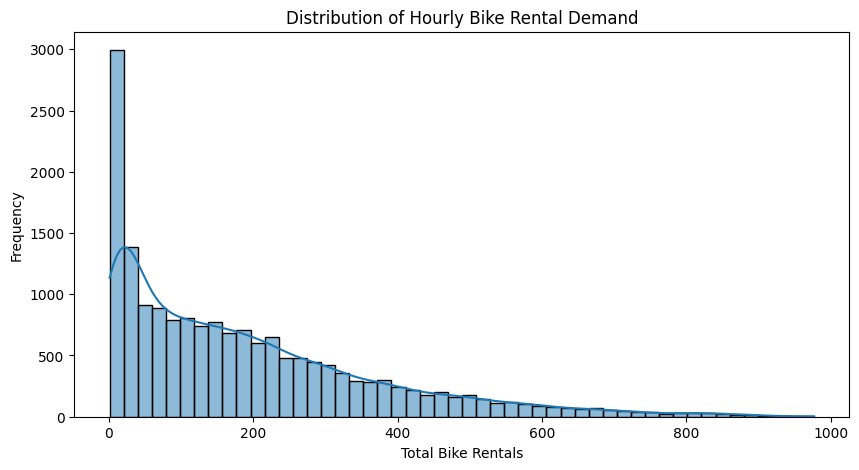

In [6]:
# check distribution of the target variable
%matplotlib inline

import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="cnt", bins=50, kde=True)

plt.title("Distribution of Hourly Bike Rental Demand")
plt.xlabel("Total Bike Rentals")
plt.ylabel("Frequency")

plt.show()

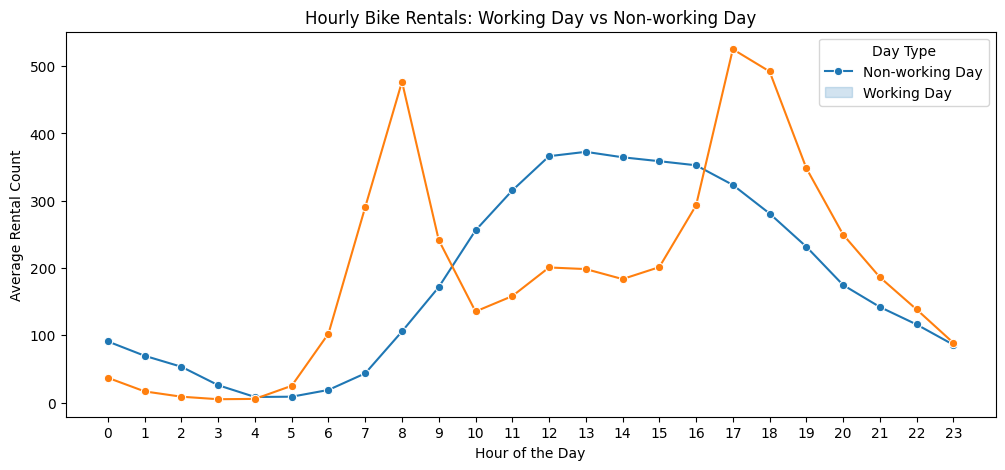

In [7]:
# 1. Working Day vs Non-working Day
workingday_demand = (
    df.groupby(["hr", "workingday"])["cnt"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=workingday_demand,
    x="hr",
    y="cnt",
    hue="workingday",
    marker="o"
)

plt.title("Hourly Bike Rentals: Working Day vs Non-working Day")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Rental Count")
plt.xticks(range(0, 24))
plt.legend(
    title="Day Type",
    labels=["Non-working Day", "Working Day"]
)
plt.show()

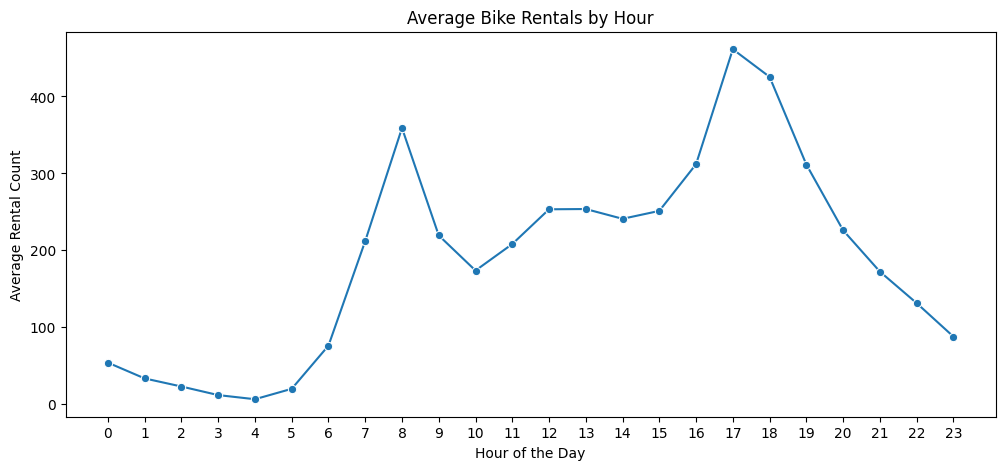

In [8]:
# 2. Hourly Demand Patterns
hourly_demand = (
    df.groupby("hr")["cnt"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=hourly_demand,
    x="hr",
    y="cnt",
    marker="o"
)

plt.title("Average Bike Rentals by Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Rental Count")
plt.xticks(range(0, 24))
plt.show()

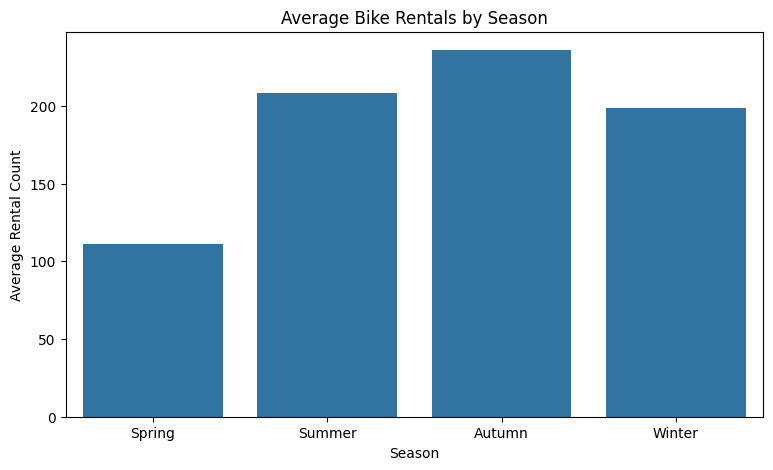

In [9]:
# 3. Seasonal Patterns
season_labels = {
    1: "Spring",
    2: "Summer",
    3: "Autumn",
    4: "Winter"
}

df["season_label"] = df["season"].map(season_labels)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="season_label",
    y="cnt",
    errorbar=None,
    order=["Spring", "Summer", "Autumn", "Winter"]
)

plt.title("Average Bike Rentals by Season")
plt.xlabel("Season")
plt.ylabel("Average Rental Count")
plt.show()

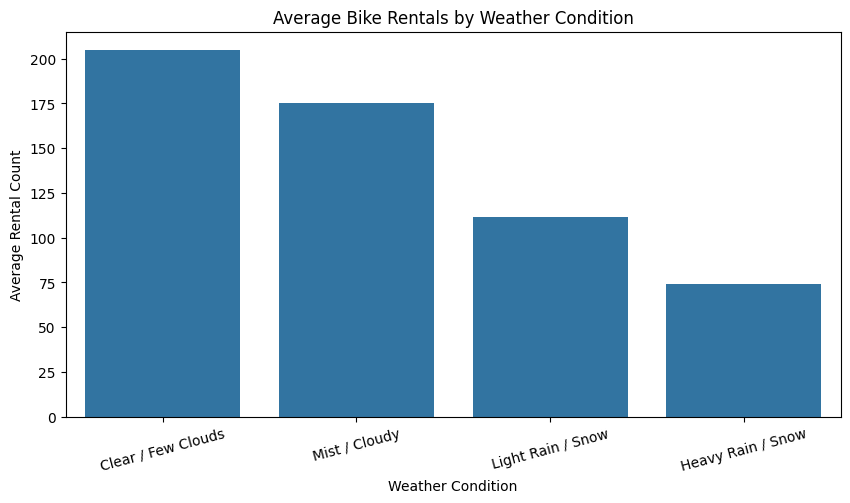

In [10]:
# 4. Weather Conditions
weather_labels = {
    1: "Clear / Few Clouds",
    2: "Mist / Cloudy",
    3: "Light Rain / Snow",
    4: "Heavy Rain / Snow"
}

df["weather_label"] = df["weathersit"].map(weather_labels)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x="weather_label",
    y="cnt",
    errorbar=None
)

plt.title("Average Bike Rentals by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Average Rental Count")
plt.xticks(rotation=15)
plt.show()

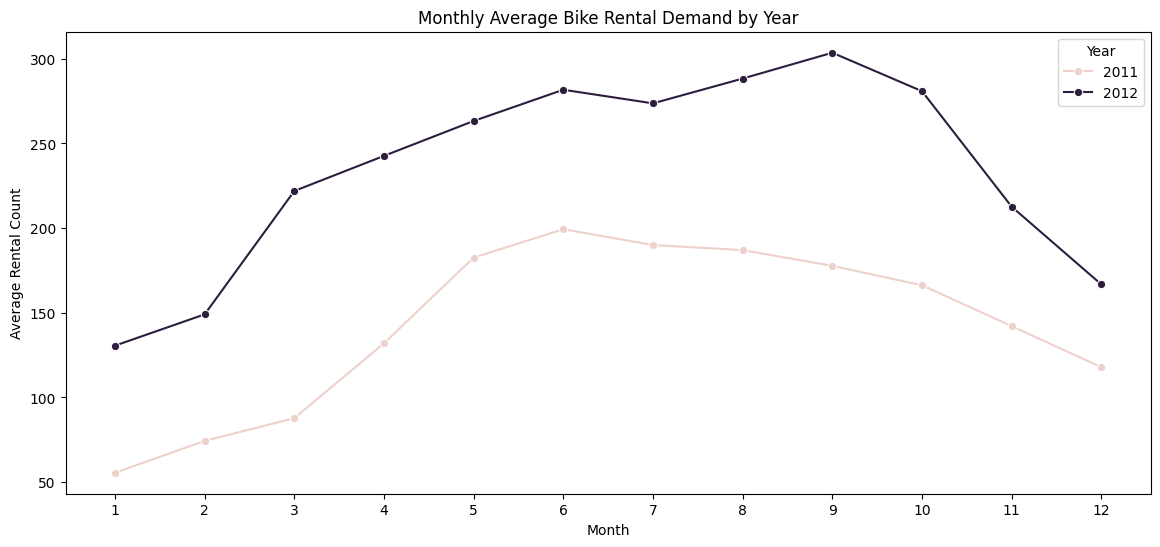

In [11]:
# 5. Monthly Demand Trends
df["dteday"] = pd.to_datetime(df["dteday"])

# extract year and month
df["year"] = df["dteday"].dt.year
df["month"] = df["dteday"].dt.month

monthly_demand = (
    df.groupby(["year", "month"])["cnt"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_demand,
    x="month",
    y="cnt",
    hue="year",
    marker="o"
)

plt.title("Monthly Average Bike Rental Demand by Year")
plt.xlabel("Month")
plt.ylabel("Average Rental Count")
plt.xticks(range(1, 13))
plt.legend(title="Year")

plt.show()

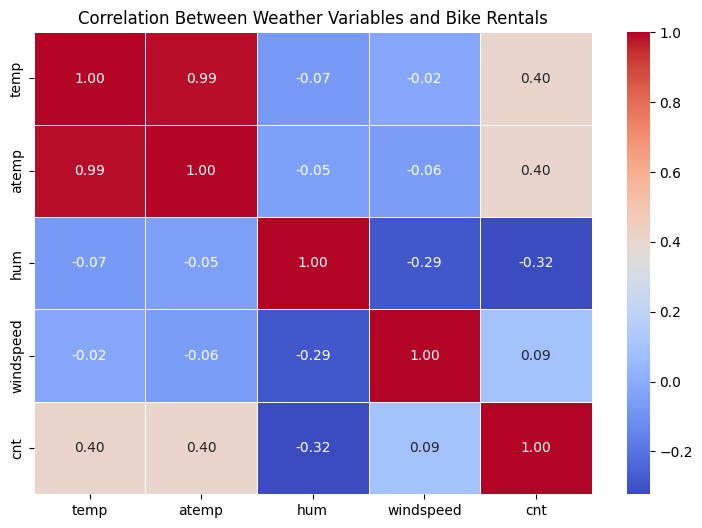

In [12]:
# 6. Correlation Analysis
correlation_features = [
    "temp",
    "atemp",
    "hum",
    "windspeed",
    "cnt"
]

correlation_matrix = df[correlation_features].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Weather Variables and Bike Rentals")
plt.show()

/Users/jiayeelee/Library/Python/3.9/lib/python/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: divide by zero encountered in matmul
  return _core_matmul(x1, x2)
/Users/jiayeelee/Library/Python/3.9/lib/python/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: overflow encountered in matmul
  return _core_matmul(x1, x2)
/Users/jiayeelee/Library/Python/3.9/lib/python/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: invalid value encountered in matmul
  return _core_matmul(x1, x2)


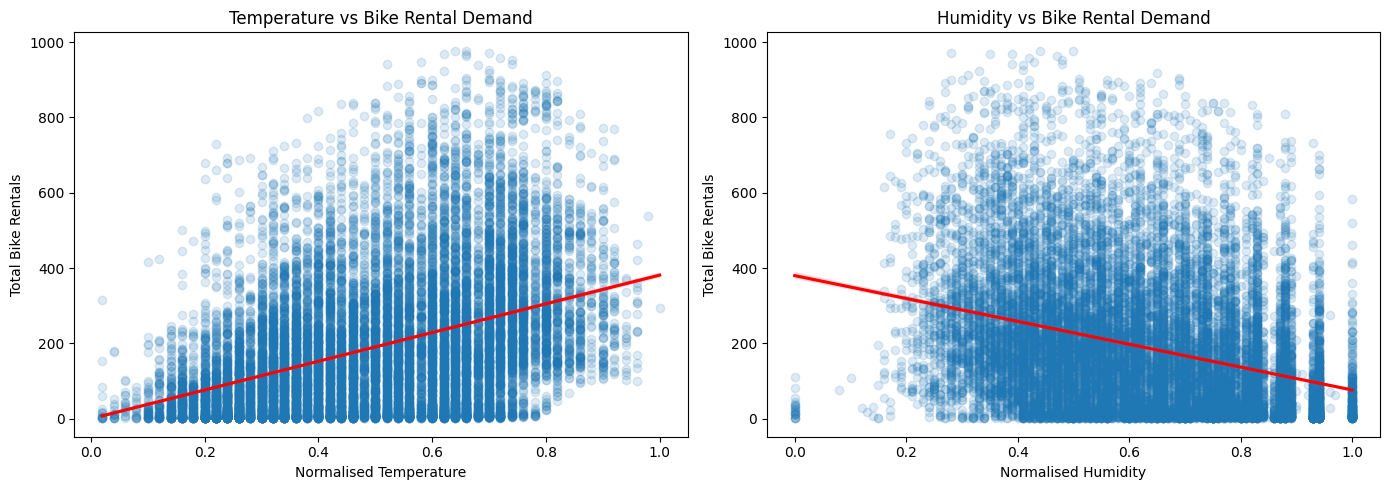

In [13]:
# check temperature and humidity relationships
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.regplot(
    data=df,
    x="temp",
    y="cnt",
    scatter_kws={"alpha": 0.15},
    line_kws={"color": "red"},
    ax=axes[0]
)

axes[0].set_title("Temperature vs Bike Rental Demand")
axes[0].set_xlabel("Normalised Temperature")
axes[0].set_ylabel("Total Bike Rentals")

sns.regplot(
    data=df,
    x="hum",
    y="cnt",
    scatter_kws={"alpha": 0.15},
    line_kws={"color": "red"},
    ax=axes[1]
)

axes[1].set_title("Humidity vs Bike Rental Demand")
axes[1].set_xlabel("Normalised Humidity")
axes[1].set_ylabel("Total Bike Rentals")

plt.tight_layout()
plt.show()

In [14]:
# seasonal demand summary
season_summary = (
    df.groupby("season_label")["cnt"]
    .agg(["mean", "median", "count"])
    .round(2)
    .sort_values("mean", ascending=False)
)

display(season_summary)

# weather demand summary
weather_summary = (
    df.groupby("weather_label")["cnt"]
    .agg(["mean", "median", "count"])
    .round(2)
    .sort_values("mean", ascending=False)
)

display(weather_summary)

,mean,median,count
season_label,,,
Autumn,236.02,199.0,4496
Summer,208.34,165.0,4409
Winter,198.87,155.5,4232
Spring,111.11,76.0,4242


,mean,median,count
weather_label,,,
Clear / Few Clouds,204.87,159.0,11413
Mist / Cloudy,175.17,133.0,4544
Light Rain / Snow,111.58,63.0,1419
Heavy Rain / Snow,74.33,36.0,3


## EDA Findings

The exploratory data analysis identified several patterns associated with hourly bike rental demand:

1. **Working Day vs Non-working Day:** Working days demonstrate prominent morning and evening demand peaks, whereas non-working days show higher demand around midday and afternoon.

2. **Hourly Demand Patterns:** Bike rental demand exhibits distinct hourly variations, with noticeable peaks during the morning and evening periods.

3. **Seasonal Patterns:** Autumn records the highest average rental demand (236.02), while spring records the lowest (111.11).

4. **Weather Conditions:** Average rental demand generally decreases under less favourable weather conditions. However, the heavy rain/snow category contains only three observations, limiting the reliability of its average demand estimate.

5. **Monthly Demand Trends:** Average hourly rental demand was consistently higher in 2012 than in 2011 across all months. Both years also exhibit seasonal fluctuations in rental demand.

6. **Correlation Analysis:** Temperature and feeling temperature show moderate positive correlations with bike rental demand (0.40), while humidity shows a negative correlation (-0.32). Wind speed has a relatively weak positive correlation (0.09).

7. **Feature Relationships:** Temperature and feeling temperature are highly correlated (0.99), indicating substantial overlap in the information they provide. Temperature also appears to have a potentially non-linear relationship with rental demand.

Overall, these observations suggest that temporal, weather-related and seasonal features should be considered during model development.

In [15]:
# create datetime feature
df["datetime"] = (
    df["dteday"] + pd.to_timedelta(df["hr"], unit="h")
)

df = df.sort_values("datetime").reset_index(drop=True)

# check missing timestamps
full_datetime_range = pd.date_range(
    start=df["datetime"].min(),
    end=df["datetime"].max(),
    freq="h"
)

missing_timestamps = full_datetime_range.difference(df["datetime"])

print(f"Date range: {df['datetime'].min()} to {df['datetime'].max()}")
print(f"Total observations: {len(df)}")
print(f"Missing timestamps: {len(missing_timestamps)}")
print(f"Duplicate timestamps: {df['datetime'].duplicated().sum()}")

Date range: 2011-01-01 00:00:00 to 2012-12-31 23:00:00
Total observations: 17379
Missing timestamps: 165
Duplicate timestamps: 0


In [16]:
import numpy as np

# create modelling dataset
model_df = df.copy()

# hour cyclical encoding
model_df["hour_sin"] = np.sin(2 * np.pi * model_df["hr"] / 24)
model_df["hour_cos"] = np.cos(2 * np.pi * model_df["hr"] / 24)

# weekday cyclical encoding
model_df["weekday_sin"] = np.sin(2 * np.pi * model_df["weekday"] / 7)
model_df["weekday_cos"] = np.cos(2 * np.pi * model_df["weekday"] / 7)

# month cyclical encoding
model_df["month_sin"] = np.sin(
    2 * np.pi * (model_df["mnth"] - 1) / 12
)
model_df["month_cos"] = np.cos(
    2 * np.pi * (model_df["mnth"] - 1) / 12
)

In [17]:
# define feature columns
feature_columns = [
    "hour_sin",
    "hour_cos",
    "weekday_sin",
    "weekday_cos",
    "month_sin",
    "month_cos",
    "yr",
    "holiday",
    "workingday",
    "season",
    "weathersit",
    "temp",
    "atemp",
    "hum",
    "windspeed"
]

X = model_df[feature_columns].copy()
y = model_df["cnt"].copy()

# convert categorical features
categorical_features = ["season", "weathersit"]
X[categorical_features] = X[categorical_features].astype("category")

print(f"Feature matrix: {X.shape}")
print(f"Target vector: {y.shape}")

Feature matrix: (17379, 15)
Target vector: (17379,)


In [18]:
# define chronological split point
split_index = int(len(X) * 0.8)

# split features
X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()

# split target
y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

# display dataset sizes
print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)

Training set: (13903, 15)
Testing set: (3476, 15)

Training target: (13903,)
Testing target: (3476,)


In [19]:
# identify the corresponding dates
train_start = model_df["datetime"].iloc[0]
train_end = model_df["datetime"].iloc[split_index - 1]

test_start = model_df["datetime"].iloc[split_index]
test_end = model_df["datetime"].iloc[-1]

In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

numerical_features = [
    col for col in feature_columns
    if col not in categorical_features
]

# create preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

In [21]:
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import os
import joblib

# create function to train, evaluate, save and plot model results
def train_evaluate_save_plot(
    model,
    model_name,
    X_train,
    X_test,
    y_train,
    y_test,
    preprocessor,
    save_dir="../saved_models",
    plot=True,
    plot_samples=200
):
    """
    Train, predict, evaluate, save and visualise a regression model.

    Returns:
        trained_pipeline: Fitted preprocessing + model pipeline
        y_pred: Predictions on test data
        metrics: Dictionary containing evaluation metrics
    """

    # 1. create model pipeline
    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", model)
    ])

    # 2. train model
    pipeline.fit(X_train, y_train)

    # 3. generate predictions
    y_pred = pipeline.predict(X_test)

    # 4. evaluate model
    metrics = {
        "Model": model_name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2": r2_score(y_test, y_pred)
    }

    # 5. save trained model
    os.makedirs(save_dir, exist_ok=True)

    model_path = os.path.join(
        save_dir,
        f"{model_name.lower().replace(' ', '_')}.joblib"
    )

    joblib.dump(pipeline, model_path)

    # 6. plot Actual vs Predicted
    if plot:
        n_samples = min(plot_samples, len(y_test))

        plt.figure(figsize=(12, 5))

        plt.plot(
            np.asarray(y_test)[:n_samples],
            label="Actual",
            linewidth=2
        )

        plt.plot(
            y_pred[:n_samples],
            label="Predicted",
            linewidth=1.5,
            alpha=0.8
        )

        plt.title(f"Actual vs Predicted - {model_name}")
        plt.xlabel("Test Observation")
        plt.ylabel("Bike Rental Count")
        plt.legend()
        plt.tight_layout()
        plt.show()

    # 7. display evaluation results
    print(f"Model: {model_name}")
    print(f"MAE:   {metrics['MAE']:.3f}")
    print(f"RMSE:  {metrics['RMSE']:.3f}")
    print(f"R²:    {metrics['R2']:.3f}")
    print(f"Saved: {model_path}")

    return pipeline, y_pred, metrics

/Users/jiayeelee/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/jiayeelee/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/jiayeelee/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


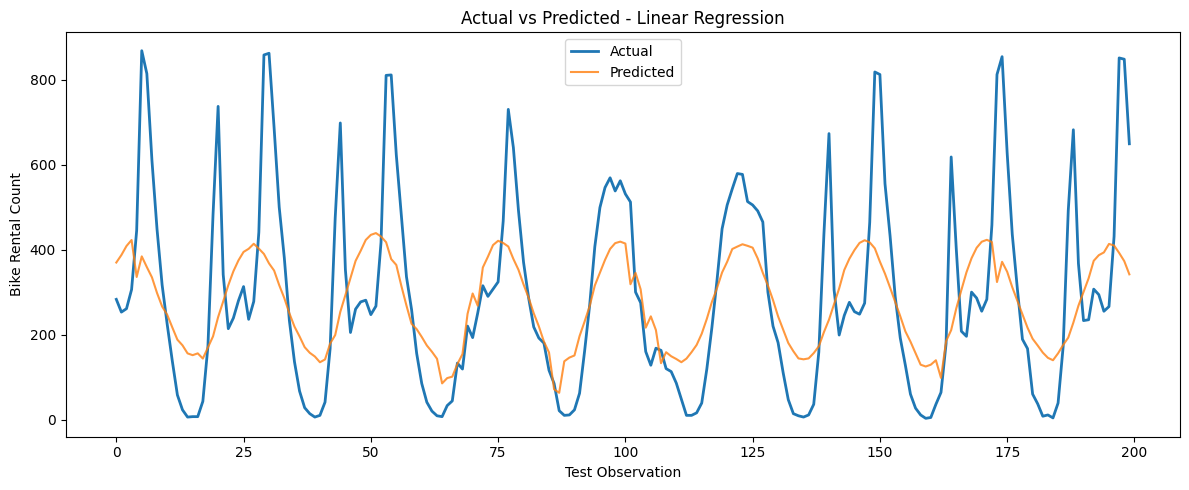

Model: Linear Regression
MAE:   120.741
RMSE:  164.409
R²:    0.444
Saved: ../saved_models/linear_regression.joblib


In [22]:
# LR model
from sklearn.linear_model import LinearRegression

lr_model, lr_predictions, lr_metrics = train_evaluate_save_plot(
    model=LinearRegression(),
    model_name="Linear Regression",
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test,
    preprocessor=preprocessor
)

/Users/jiayeelee/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/jiayeelee/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/jiayeelee/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/jiayeelee/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/jiayeelee/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/jiayeelee/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ 

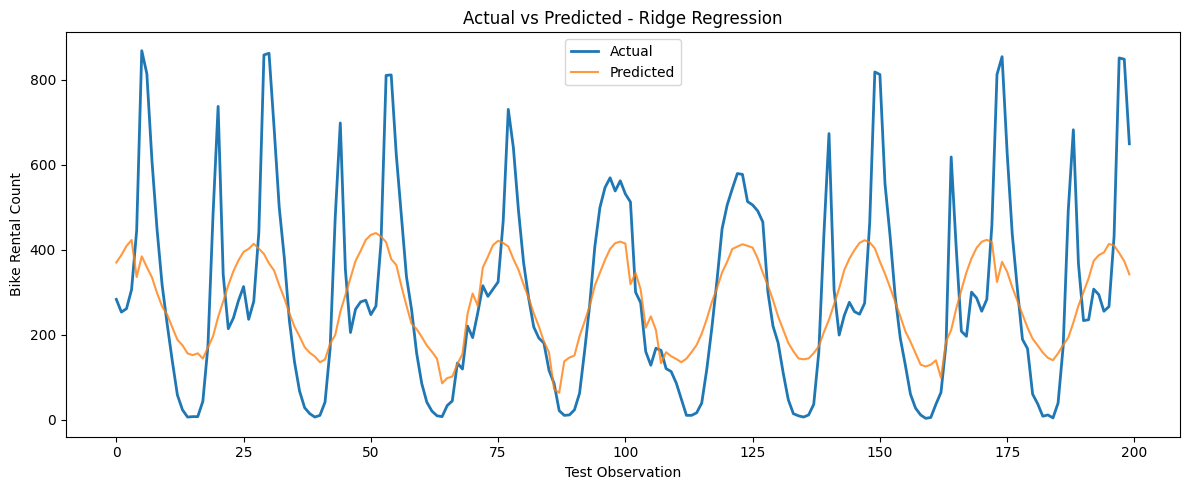

Model: Ridge Regression
MAE:   120.738
RMSE:  164.411
R²:    0.444
Saved: ../saved_models/ridge_regression.joblib


In [23]:
# Ridge Regression model
from sklearn.linear_model import Ridge

ridge_model, ridge_predictions, ridge_metrics = train_evaluate_save_plot(
    model=Ridge(alpha=1.0),
    model_name="Ridge Regression",
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test,
    preprocessor=preprocessor
)

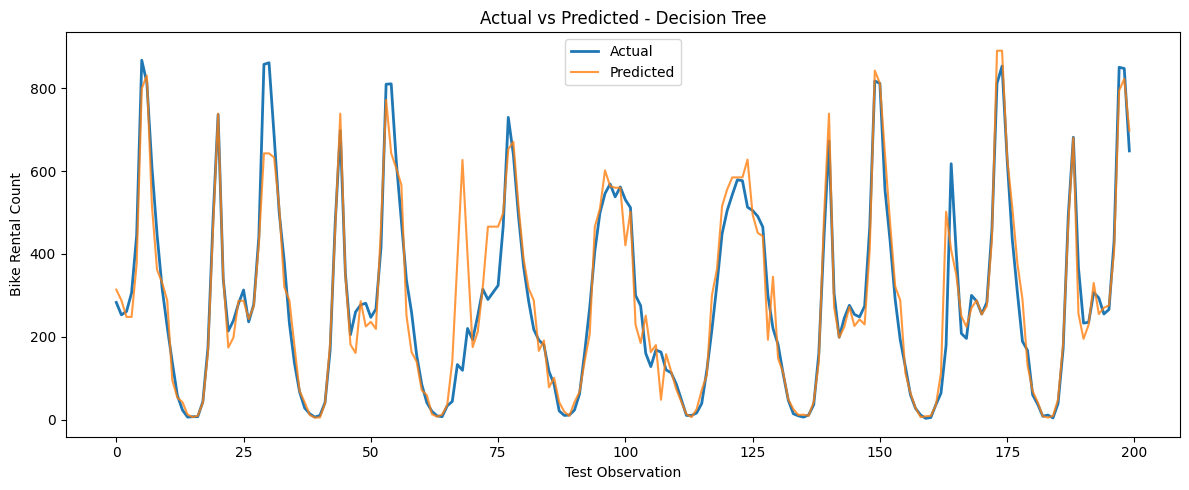

Model: Decision Tree
MAE:   58.831
RMSE:  91.371
R²:    0.828
Saved: ../saved_models/decision_tree.joblib


In [24]:
# DT model
from sklearn.tree import DecisionTreeRegressor

dt_model, dt_predictions, dt_metrics = train_evaluate_save_plot(
    model=DecisionTreeRegressor(
        random_state=42
    ),
    model_name="Decision Tree",
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test,
    preprocessor=preprocessor
)

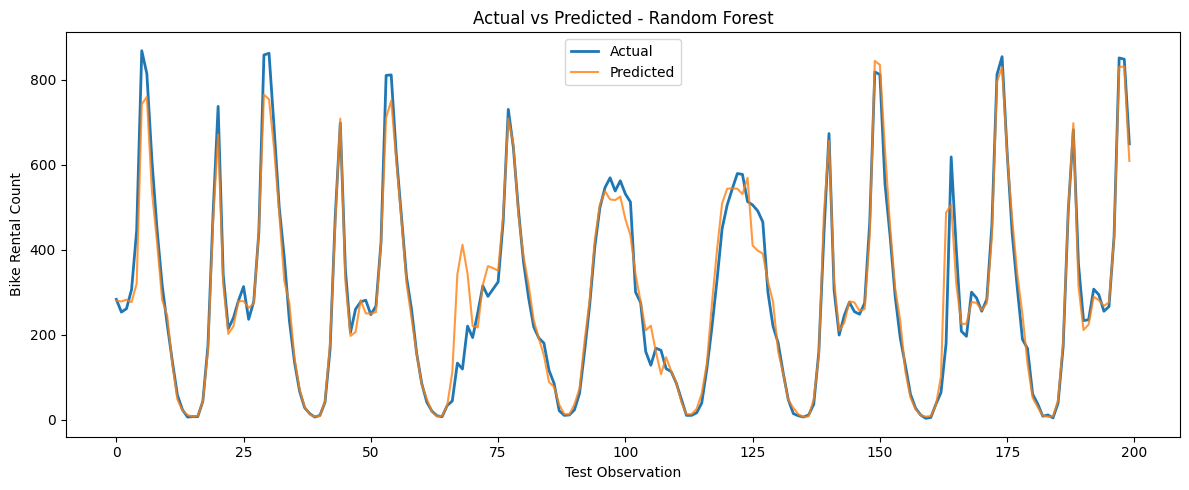

Model: Random Forest
MAE:   51.188
RMSE:  76.811
R²:    0.879
Saved: ../saved_models/random_forest.joblib


In [25]:
# RF model
from sklearn.ensemble import RandomForestRegressor

rf_model, rf_predictions, rf_metrics = train_evaluate_save_plot(
    model=RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
    model_name="Random Forest",
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test,
    preprocessor=preprocessor
)

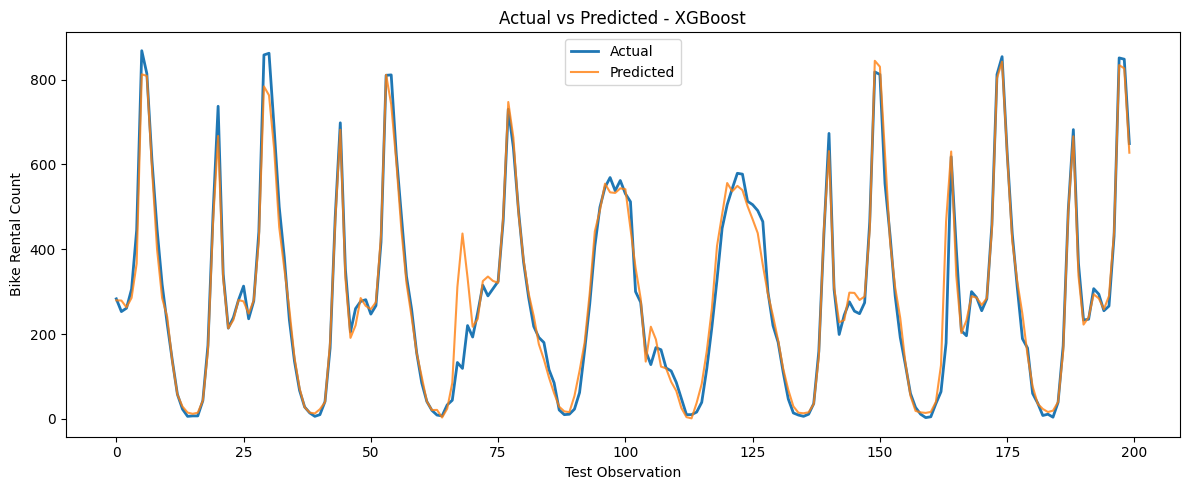

Model: XGBoost
MAE:   44.946
RMSE:  68.084
R²:    0.905
Saved: ../saved_models/xgboost.joblib


In [26]:
# XGBoost model
from xgboost import XGBRegressor

xgb_model, xgb_predictions, xgb_metrics = train_evaluate_save_plot(
    model=XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        random_state=42,
        n_jobs=-1,
        objective="reg:squarederror"
    ),
    model_name="XGBoost",
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test,
    preprocessor=preprocessor
)


/Users/jiayeelee/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


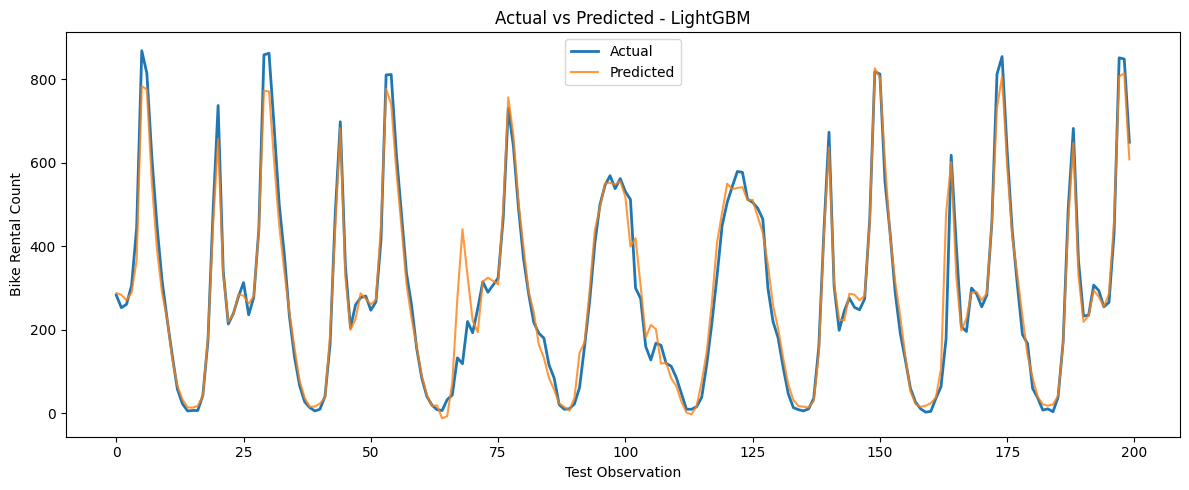

Model: LightGBM
MAE:   45.402
RMSE:  68.806
R²:    0.903
Saved: ../saved_models/lightgbm.joblib


In [27]:
# LightGBM model
from lightgbm import LGBMRegressor

lgbm_model, lgbm_predictions, lgbm_metrics = train_evaluate_save_plot(
    model=LGBMRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    ),
    model_name="LightGBM",
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test,
    preprocessor=preprocessor
)

In [28]:
# final model comparison
results_df = pd.DataFrame([
    lr_metrics,
    ridge_metrics,
    dt_metrics,
    rf_metrics,
    xgb_metrics,
    lgbm_metrics
])

results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

display(results_df)

,Model,MAE,RMSE,R2
0,XGBoost,44.946438,68.083829,0.904648
1,LightGBM,45.402435,68.806021,0.902614
2,Random Forest,51.187798,76.811193,0.878636
3,Decision Tree,58.830552,91.371350,0.828263
4,Linear Regression,120.740794,164.408741,0.443977
5,Ridge Regression,120.737572,164.411428,0.443959


In [29]:
# XGBoost Hyperparameter Tuning
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV

xgb_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", XGBRegressor(
        objective="reg:squarederror",
        random_state=42,
        n_jobs=1
    ))
])

param_distributions = {
    "model__n_estimators": [200, 300, 500, 700],
    "model__max_depth": [3, 4, 5, 6, 8],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "model__subsample": [0.7, 0.8, 0.9, 1.0],
    "model__colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "model__min_child_weight": [1, 3, 5, 7],
    "model__reg_lambda": [0.1, 1, 5, 10]
}

tscv = TimeSeriesSplit(n_splits=3)

xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_distributions,
    n_iter=20,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

xgb_search.fit(X_train, y_train)

print("Best Parameters:")
print(xgb_search.best_params_)

print("\nBest Cross-Validation MAE:")
print(-xgb_search.best_score_)


Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best Parameters:
{'model__subsample': 0.7, 'model__reg_lambda': 0.1, 'model__n_estimators': 500, 'model__min_child_weight': 5, 'model__max_depth': 6, 'model__learning_rate': 0.03, 'model__colsample_bytree': 1.0}

Best Cross-Validation MAE:
51.55179341634115


In [30]:
# retrieve the best XGBoost pipeline
best_xgb_model = xgb_search.best_estimator_

# predict on the untouched test set
y_pred_xgb_tuned = best_xgb_model.predict(X_test)

# evaluate
tuned_xgb_results = {
    "Model": "XGBoost Tuned",
    "MAE": mean_absolute_error(y_test, y_pred_xgb_tuned),
    "RMSE": np.sqrt(mean_squared_error(y_test, y_pred_xgb_tuned)),
    "R2": r2_score(y_test, y_pred_xgb_tuned)
}

pd.DataFrame([tuned_xgb_results]).round(3)

,Model,MAE,RMSE,R2
0,XGBoost Tuned,43.726,66.231,0.91


In [31]:
# LightGBM Hyperparameter Tuning
import lightgbm as lgb

lgb_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", lgb.LGBMRegressor(
        objective="regression",
        random_state=42,
        n_jobs=1,
        verbosity=-1
    ))
])

lgb_param_distributions = {
    "model__n_estimators": [200, 300, 500, 700],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "model__max_depth": [-1, 3, 5, 7, 10],
    "model__num_leaves": [15, 20, 31, 40, 50],
    "model__min_child_samples": [10, 20, 30, 50],
    "model__subsample": [0.7, 0.8, 0.9, 1.0],
    "model__colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "model__reg_lambda": [0.1, 1, 5, 10]
}

lgb_search = RandomizedSearchCV(
    estimator=lgb_pipeline,
    param_distributions=lgb_param_distributions,
    n_iter=20,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

lgb_search.fit(X_train, y_train)

print("Best Parameters:")
print(lgb_search.best_params_)

print("\nBest Cross-Validation MAE:")
print(-lgb_search.best_score_)

Fitting 3 folds for each of 20 candidates, totalling 60 fits


/Users/jiayeelee/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/Users/jiayeelee/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/Users/jiayeelee/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/Users/jiayeelee/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/Users/jiayeelee/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegress

Best Parameters:
{'model__subsample': 1.0, 'model__reg_lambda': 0.1, 'model__num_leaves': 31, 'model__n_estimators': 300, 'model__min_child_samples': 20, 'model__max_depth': 5, 'model__learning_rate': 0.05, 'model__colsample_bytree': 0.7}

Best Cross-Validation MAE:
52.87564484542676


In [32]:
best_lgb_model = lgb_search.best_estimator_

y_pred_lgb_tuned = best_lgb_model.predict(X_test)

tuned_lgb_results = {
    "Model": "LightGBM Tuned",
    "MAE": mean_absolute_error(y_test, y_pred_lgb_tuned),
    "RMSE": np.sqrt(mean_squared_error(y_test, y_pred_lgb_tuned)),
    "R2": r2_score(y_test, y_pred_lgb_tuned)
}

pd.DataFrame([tuned_lgb_results]).round(3)

/Users/jiayeelee/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


,Model,MAE,RMSE,R2
0,LightGBM Tuned,49.186,72.672,0.891


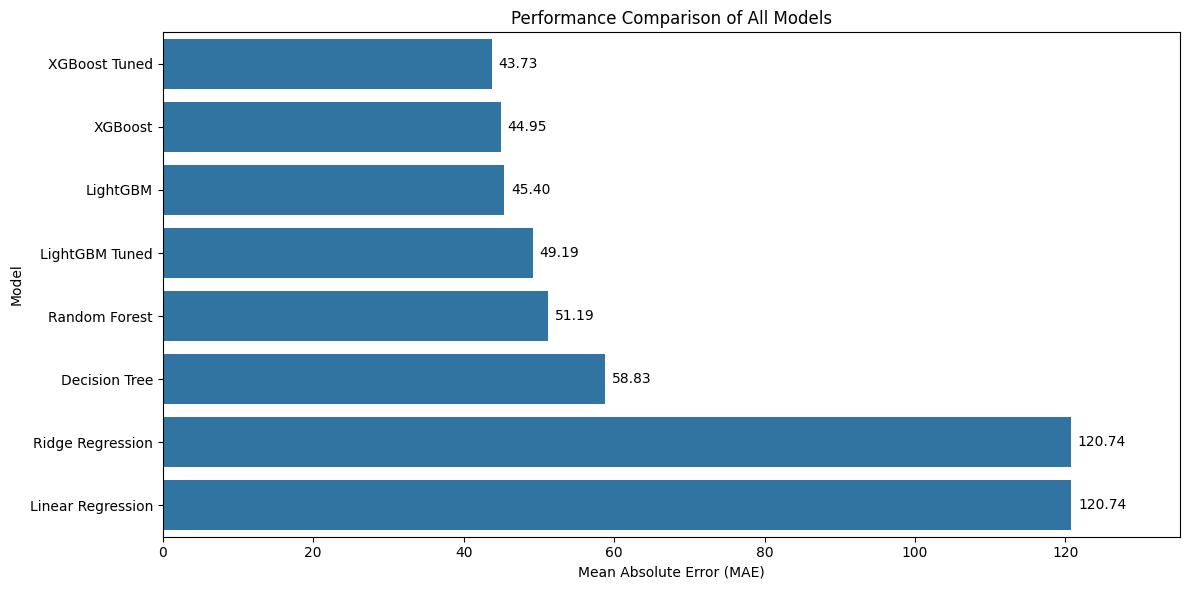

In [33]:
# combine baseline and tuned model results
final_results = pd.concat(
    [
        results_df,
        pd.DataFrame([
            tuned_xgb_results,
            tuned_lgb_results
        ])
    ],
    ignore_index=True
)

final_results = (
    final_results
    .sort_values("MAE")
    .reset_index(drop=True)
)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=final_results,
    x="MAE",
    y="Model"
)

# add MAE labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=5)

plt.title("Performance Comparison of All Models")
plt.xlabel("Mean Absolute Error (MAE)")
plt.ylabel("Model")
plt.xlim(0, final_results["MAE"].max() * 1.12)

plt.tight_layout()
plt.show()

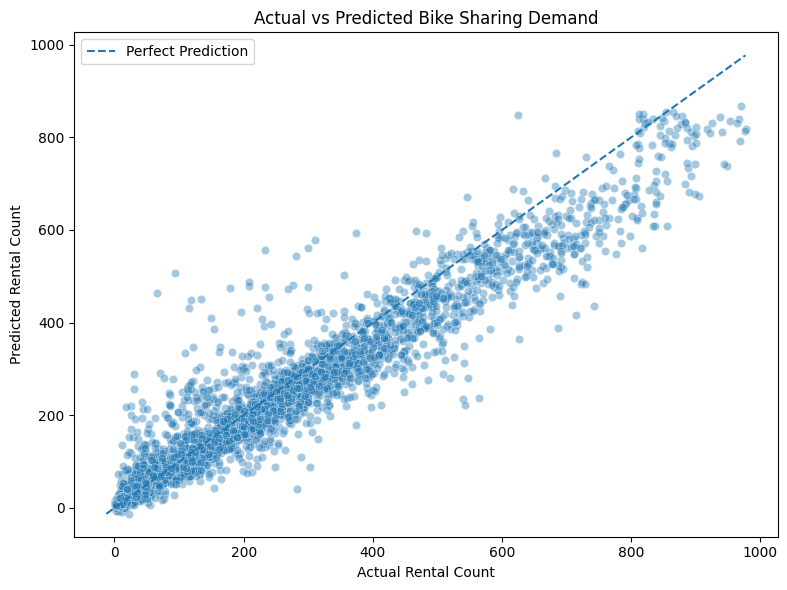

In [34]:
# create a comparison DataFrame
prediction_df = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred_xgb_tuned
})

# Plot Actual vs Predicted
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=prediction_df,
    x="Actual",
    y="Predicted",
    alpha=0.4
)

# add a reference line
min_value = min(prediction_df["Actual"].min(),
                prediction_df["Predicted"].min())

max_value = max(prediction_df["Actual"].max(),
                prediction_df["Predicted"].max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    label="Perfect Prediction"
)

plt.title("Actual vs Predicted Bike Sharing Demand")
plt.xlabel("Actual Rental Count")
plt.ylabel("Predicted Rental Count")
plt.legend()
plt.tight_layout()
plt.show()

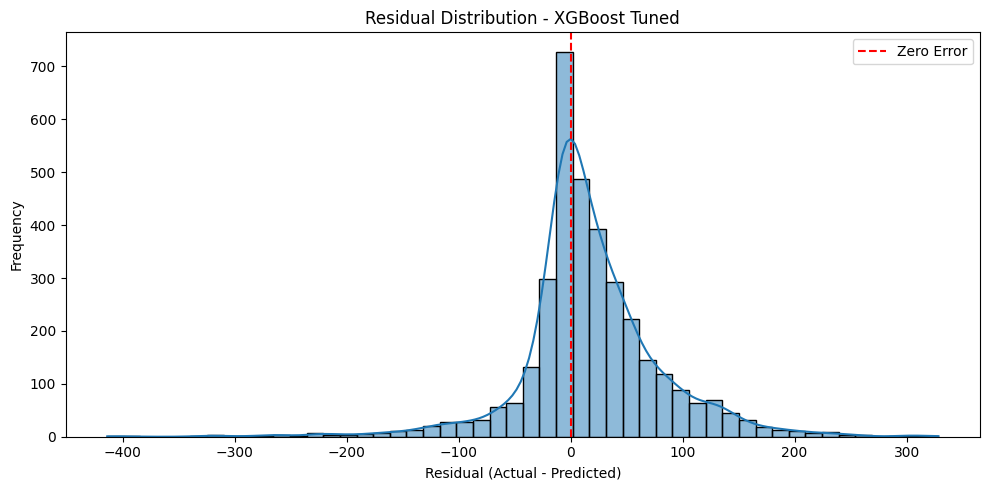

In [35]:
# plot residual distribution
prediction_df["Residual"] = (
    prediction_df["Actual"] - prediction_df["Predicted"]
)

plt.figure(figsize=(10, 5))

sns.histplot(
    prediction_df["Residual"],
    bins=50,
    kde=True
)

plt.axvline(
    0,
    color="red",
    linestyle="--",
    label="Zero Error"
)

plt.title("Residual Distribution - XGBoost Tuned")
plt.xlabel("Residual (Actual - Predicted)")
plt.ylabel("Frequency")
plt.legend()

plt.tight_layout()
plt.show()

In [36]:
# calculate residual statistics
residual_stats = prediction_df["Residual"].describe()

print("Residual Statistics:")
display(residual_stats)

print("Skewness:", prediction_df["Residual"].skew())

Residual Statistics:


count    3476.000000
mean       18.125379
std        63.712045
min      -413.689331
25%        -8.876144
50%        10.724159
75%        45.549969
max       328.395828
Name: Residual, dtype: float64

Skewness: -0.21131739407550781


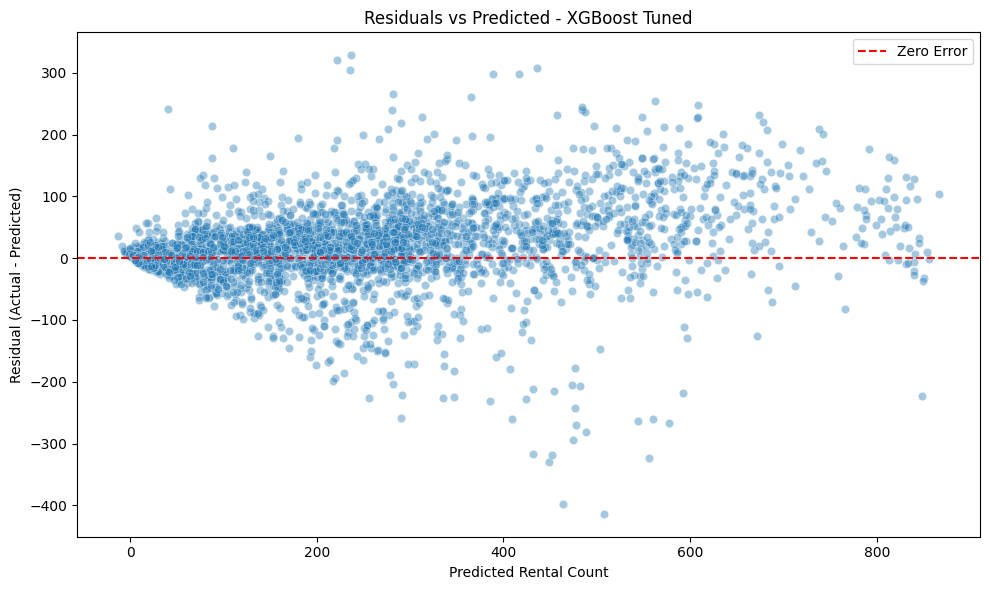

In [37]:
# plot residuals against predicted values
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=prediction_df,
    x="Predicted",
    y="Residual",
    alpha=0.4
)

plt.axhline(
    0,
    color="red",
    linestyle="--",
    label="Zero Error"
)

plt.title("Residuals vs Predicted - XGBoost Tuned")
plt.xlabel("Predicted Rental Count")
plt.ylabel("Residual (Actual - Predicted)")
plt.legend()

plt.tight_layout()
plt.show()

In [38]:
# check negative predictions
negative_predictions = prediction_df[
    prediction_df["Predicted"] < 0
]

print("Total Predictions:", len(prediction_df))
print("Negative Predictions:", len(negative_predictions))

print(
    "Percentage of Negative Predictions:",
    round(len(negative_predictions) / len(prediction_df) * 100, 2),
    "%"
)

# Display negative predictions, if any
display(negative_predictions.head(10))

Total Predictions: 3476
Negative Predictions: 12
Percentage of Negative Predictions: 0.35 %


,Actual,Predicted,Residual
13967,7,-6.473749,13.473749
14543,11,-2.757892,13.757892
14901,4,-3.913836,7.913836
14903,7,-0.816576,7.816576
15405,7,-3.302967,10.302967
15406,3,-5.503407,8.503407
16208,11,-8.085875,19.085875
16209,5,-6.920367,11.920367
16667,16,-0.456532,16.456532
16836,23,-12.540087,35.540087


In [39]:
# compare raw vs clipped predictions

# apply clipping: negative predictions become zero
y_pred_xgb_clipped = np.maximum(y_pred_xgb_tuned, 0)

prediction_comparison = pd.DataFrame([
    {
        "Prediction": "Raw",
        "MAE": mean_absolute_error(y_test, y_pred_xgb_tuned),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred_xgb_tuned)),
        "R2": r2_score(y_test, y_pred_xgb_tuned)
    },
    {
        "Prediction": "Clipped",
        "MAE": mean_absolute_error(y_test, y_pred_xgb_clipped),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred_xgb_clipped)),
        "R2": r2_score(y_test, y_pred_xgb_clipped)
    }
])

display(prediction_comparison.round(3))

,Prediction,MAE,RMSE,R2
0,Raw,43.726,66.231,0.91
1,Clipped,43.711,66.228,0.91


### Model Diagnostics – XGBoost Tuned

The diagnostic analysis was conducted to evaluate the prediction behaviour and reliability of the tuned XGBoost model beyond its overall evaluation metrics.

**Key Findings:**

1. **Actual vs Predicted:** The predicted values generally align with the actual rental counts, indicating that the model captures the overall demand patterns reasonably well. However, larger deviations are observed during high-demand periods, suggesting that the model has difficulty accurately predicting peak rental demand.

2. **Residual Distribution:** Most residuals are concentrated around zero, with a mean of 18.13 and a median of 10.72. The positive mean residual indicates a slight overall tendency to underestimate rental demand. The distribution also exhibits long tails, indicating the presence of relatively large prediction errors.

3. **Residuals vs Predicted:** The residual spread increases as predicted rental counts increase. This pattern suggests potential heteroscedasticity, indicating that prediction errors are not equally distributed across different demand levels. Larger variations are particularly noticeable in higher-demand periods.

4. **Negative Predictions:** Out of 3,476 test predictions, 12 (0.35%) were negative. Since negative rental counts are not practically meaningful, clipping was applied to set negative predictions to zero.

5. **Raw vs Clipped Predictions:** Clipping slightly improved the MAE from 43.726 to 43.711 and RMSE from 66.231 to 66.228, while the R² score remained approximately 0.910. This indicates that negative predictions had a negligible effect on overall model performance.

\
**Overall Conclusion:**

The tuned XGBoost model demonstrates good overall predictive performance, achieving an MAE of 43.726, RMSE of 66.231, and R² of 0.910 on the test set. Nevertheless, the diagnostic results reveal limitations in predicting high-demand periods, where prediction errors exhibit greater variability. Although negative predictions occur infrequently, clipping provides a simple post-processing measure to ensure non-negative rental count predictions. These findings highlight the importance of evaluating prediction behaviour alongside aggregate performance metrics.

In [40]:
fitted_preprocessor = best_xgb_model.named_steps["preprocessor"]
fitted_xgb = best_xgb_model.named_steps["model"]

# get feature names after preprocessing
feature_names = fitted_preprocessor.get_feature_names_out()

# get feature importance scores
feature_importances = fitted_xgb.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_importances
})

# sort by importance
importance_df = (
    importance_df
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

display(importance_df.round(4))

,Feature,Importance
0,num__hour_sin,0.1866
1,num__hour_cos,0.1509
2,num__workingday,0.1429
3,num__yr,0.1198
4,num__atemp,0.0771
5,num__temp,0.0731
6,cat__season_1,0.0531
7,cat__weathersit_3,0.0490
8,cat__season_4,0.0391
9,cat__weathersit_1,0.0171


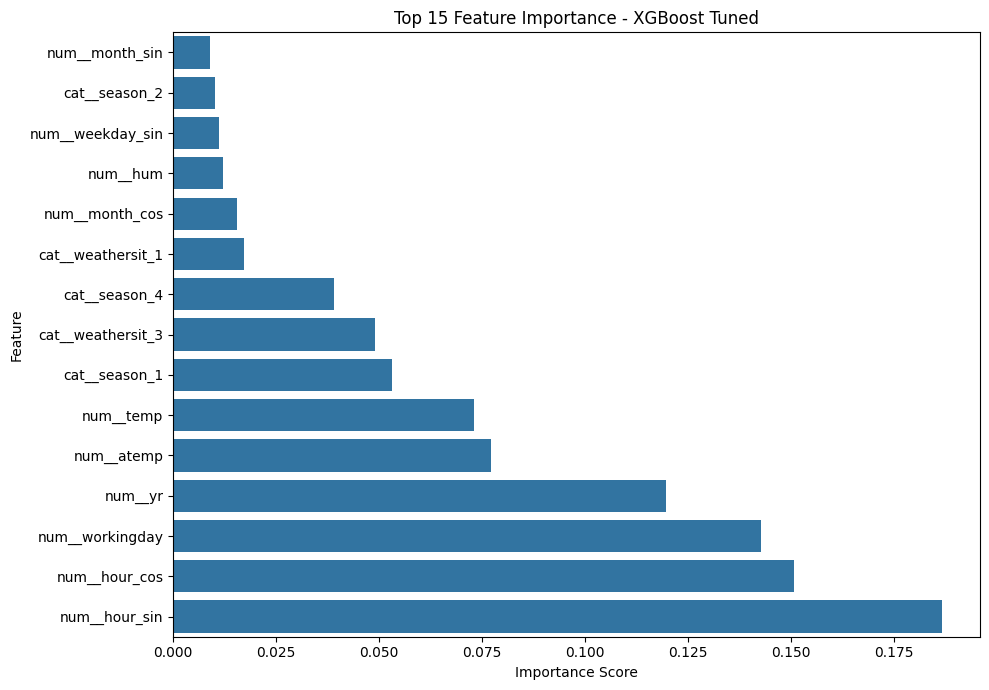

In [41]:
# select top 15 features
top_features = importance_df.head(15).sort_values(
    "Importance",
    ascending=True
)

# plot feature importance
plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Feature Importance - XGBoost Tuned")
plt.xlabel("Importance Score")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [42]:
# calculate permutation importance
from sklearn.inspection import permutation_importance

perm_importance = permutation_importance(
    best_xgb_model,
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=10,
    random_state=42,
    n_jobs=1
)

permutation_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm_importance.importances_mean,
    "Std": perm_importance.importances_std
})

# sort by importance
permutation_df = (
    permutation_df
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

display(permutation_df.round(4))

,Feature,Importance,Std
0,hour_sin,108.6903,1.3365
1,hour_cos,88.8128,1.6819
2,workingday,34.9190,0.9665
3,temp,15.2452,0.4261
4,atemp,8.3764,0.3644
5,hum,7.6453,0.3342
6,weekday_sin,4.1428,0.1571
7,weekday_cos,3.3748,0.1587
8,weathersit,3.0750,0.2021
9,season,1.7588,0.0895


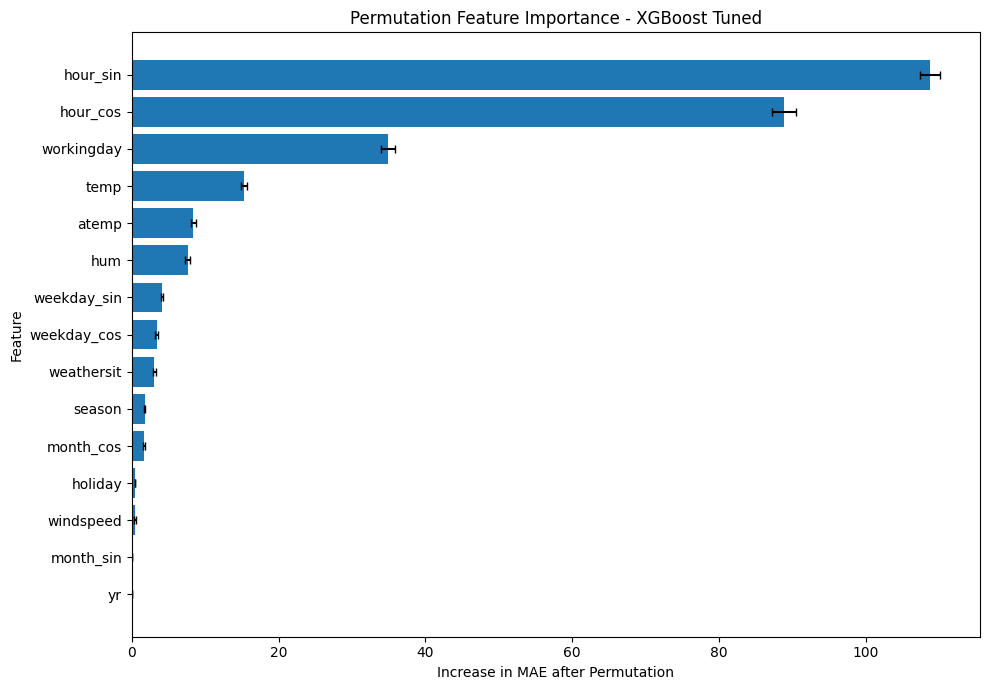

In [43]:
# select top 15 features
top_permutation = permutation_df.sort_values(
    "Importance",
    ascending=True
)

# plot permutation importance
plt.figure(figsize=(10, 7))

plt.barh(
    top_permutation["Feature"],
    top_permutation["Importance"],
    xerr=top_permutation["Std"],
    capsize=3
)

plt.title("Permutation Feature Importance - XGBoost Tuned")
plt.xlabel("Increase in MAE after Permutation")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [44]:
# compare feature importance results
importance_comparison = pd.merge(
    importance_df[["Feature", "Importance"]].assign(
        Feature=lambda x: x["Feature"].str.replace(
            "num__", "", regex=False
        ).str.replace("cat__", "", regex=False)
    ),
    permutation_df[["Feature", "Importance"]],
    on="Feature",
    how="outer",
    suffixes=("_Built-in", "_Permutation")
)

# sort by permutation importance
importance_comparison = importance_comparison.sort_values(
    "Importance_Permutation",
    ascending=False
).reset_index(drop=True)

display(importance_comparison.round(4))

,Feature,Importance_Built-in,Importance_Permutation
0,hour_sin,0.1866,108.6903
1,hour_cos,0.1509,88.8128
2,workingday,0.1429,34.9190
3,temp,0.0731,15.2452
4,atemp,0.0771,8.3764
5,hum,0.0122,7.6453
6,weekday_sin,0.0110,4.1428
7,weekday_cos,0.0084,3.3748
8,weathersit,NaN,3.0750
9,season,NaN,1.7588


### Feature Importance Analysis – Key Findings

Feature importance analysis was conducted using two methods: **XGBoost Built-in Feature Importance** and **Permutation Importance**.

The key findings are summarised as follows:

- **Time-related features** (`hour_sin` and `hour_cos`) were consistently ranked as the two most important predictors across both methods, highlighting the influence of hourly demand patterns on bike-sharing usage.
- **Working-day status** was the third most important feature in both methods, indicating its relevance to rental demand prediction.
- **Temperature features** (`temp` and `atemp`) also contributed to model performance, while humidity showed greater importance under permutation analysis.
- Differences in feature rankings were observed, particularly for `yr`, suggesting that a feature used during model training may not necessarily have a substantial impact on test-set predictive performance.
- Categorical features such as `season` and `weathersit` were evaluated at different levels of granularity due to One-Hot Encoding in the built-in method.

Overall, both methods consistently identified hourly patterns and working-day status as the leading predictors. Using both approaches provides complementary insights into the features influencing the XGBoost Tuned model's predictions.

**Note:** Feature importance indicates predictive relevance rather than causality or the direction of a feature's effect.

In [45]:
# identify the best model based on MAE
best_model_row = final_results.loc[
    final_results["MAE"].idxmin()
]

print("Best Model:", best_model_row["Model"])
print("MAE:", round(best_model_row["MAE"], 3))
print("RMSE:", round(best_model_row["RMSE"], 3))
print("R2 Score:", round(best_model_row["R2"], 3))

Best Model: XGBoost Tuned
MAE: 43.726
RMSE: 66.231
R2 Score: 0.91


### Final Model Selection

XGBoost Tuned was selected as the final model based on its overall performance on the test set. Among the eight evaluated models, it achieved the lowest MAE (43.726) and RMSE (66.231), together with the highest R² score (0.910).

Hyperparameter tuning improved the baseline XGBoost model, reducing MAE by approximately 2.71% and RMSE by 2.72%, while increasing R² from 0.905 to 0.910.

Although LightGBM demonstrated competitive baseline performance, its tuned version did not improve upon the baseline results. Therefore, XGBoost Tuned was selected as the preferred model for this project.

Residual analysis revealed some limitations, including larger prediction errors at higher demand levels, slight overall underestimation, and a small number of negative predictions. Applying a zero lower bound to predictions produced a marginal improvement in evaluation metrics.

Overall, XGBoost Tuned provided the best balance of predictive performance among the evaluated models.

In [46]:
# confirm the selected model
print("Selected Model:", "XGBoost Tuned")
print("Model Type:", type(best_xgb_model).__name__)
print("Pipeline Steps:", best_xgb_model.named_steps.keys())

Selected Model: XGBoost Tuned
Model Type: Pipeline
Pipeline Steps: dict_keys(['preprocessor', 'model'])


In [47]:
# define project directory
project_dir = os.path.join(
    os.path.expanduser("~"),
    "Downloads",
    "bike+sharing+dataset",
    "saved_models"
)

# define model directory
model_dir = os.path.join(project_dir, "best_model")

os.makedirs(model_dir, exist_ok=True)

# Save trained model
model_path = os.path.join(
    model_dir,
    "xgboost_tuned_model.pkl"
)

joblib.dump(best_xgb_model, model_path)

print("Model saved successfully!")
print("Saved Path:", model_path)

Model saved successfully!
Saved Path: /Users/jiayeelee/Downloads/bike+sharing+dataset/saved_models/best_model/xgboost_tuned_model.pkl


In [48]:
# load saved model
loaded_model = joblib.load(model_path)

# generate predictions
loaded_predictions = loaded_model.predict(X_test)

# compare with original predictions
predictions_match = np.allclose(
    loaded_predictions,
    y_pred_xgb_tuned
)

print("Model Loaded Successfully:", isinstance(loaded_model, Pipeline))
print("Prediction Shape:", loaded_predictions.shape)
print("Predictions Match Original:", predictions_match)

Model Loaded Successfully: True
Prediction Shape: (3476,)
Predictions Match Original: True
